# MD-EXAFS with your own trajectory

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nmarcella/feffGPU/blob/main/tutorials/02_md_exafs_your_trajectory.ipynb)

This notebook computes the EXAFS spectrum of a trajectory that you provide, and optionally compares it with your
measured spectrum. You fill in two cells (the files and the settings); the rest runs as it is. The steps are
explained in the first notebook, [01_md_exafs_iron.ipynb](https://github.com/nmarcella/feffGPU/blob/main/tutorials/01_md_exafs_iron.ipynb).

As it stands, the notebook runs on the synthetic iron trajectory of the first notebook, so that you can see it work
before you put in your own file.

**On Colab, choose a GPU first:** menu *Runtime → Change runtime type → T4 GPU*. Then run the cells from the top.

**Your files stay in your Colab session.** The notebook sends nothing anywhere else. Colab deletes the files of a
session when it ends; the last cell downloads the results.

## 1. Install and check

On Colab, the next cell downloads the repository (about 100 MB, most of it the table of free atoms that the
potentials start from) and installs the package. On your own computer the cell installs nothing: install `feffgpu`
first (`pip install -e .` in a checkout of the repository) and start Jupyter in the `tutorials` folder.

In [1]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and not Path("feffGPU").exists():
    !git clone --depth 1 https://github.com/nmarcella/feffGPU.git
    !pip install -q ./feffGPU
REPO = Path("feffGPU") if IN_COLAB else Path("..")    # the checkout of the repository

`feffgpu doctor` reports the GPU, the versions, and whether the package's compiled GPU routines pass their test on
this machine.

In [2]:
!feffgpu doctor

feffgpu 0.2.0, Python 3.12.3, PyTorch 2.14.1+cu126 (CUDA build 12.6)
  GPU 0: NVIDIA GeForce RTX 3080 Ti, 11.24 of 11.63 GB free
  GPU kernels of the radial solver: in use (Triton 3.8.0, a version they were tested with); they reproduce the plain code to 4e-14
  free-atom table: 99 element files in .../src/feffgpu/data/atoms
  FEFF 8.5L library (optional): not found (optional; needed only for ION / UNFREEZEF cards, rebuilding the free-atom table, and the oracle tests (fortran/README.md))
  packages: numpy 2.5.4, scipy 1.18.1, ase 3.29.0, h5py 3.16.0, pydantic 2.14.3, matplotlib 3.11.2, larch 2026.3.1, mcp installed
  not installed: MDAnalysis: not installed (optional: pip install 'feffgpu[mda]'); mace: not installed (optional: pip install 'feffgpu[mace]')
OK


The last line must be `OK`.

- **No GPU in the report:** on Colab, choose the GPU runtime (top of this notebook) and run the cells again. The
  package also runs on a CPU, slowly: set `devices = "cpu"` in the configuration below.
- **The line about the GPU kernels reports a failed test:** follow the instruction it prints. It names the setting
  `FEFFGPU_KERNELS=0`, which selects the slower plain code; in a notebook that is a cell with `%env FEFFGPU_KERNELS=0`.

## 2. Your files

Set `USE_EXAMPLE = False` to use your own trajectory. Then either

- give the path of a file that is already in the session (for example on a mounted Google Drive) in `TRAJECTORY`, or
- leave `TRAJECTORY` empty: on Colab an upload dialog opens.

`MEASURED_CHI` is optional: a text file with the columns k (1/Å) and chi(k). Files written by Athena and xraylarch
are read as they are. Leave it empty to skip the comparison.

Formats that are read directly: extended xyz, LAMMPS text dumps, VASP XDATCAR, CP2K xyz and ASE trajectories
([Trajectories](https://github.com/nmarcella/feffGPU/blob/main/docs/md/trajectories.md)).

In [3]:
import shutil

USE_EXAMPLE = True      #@param {type:"boolean"}
TRAJECTORY = ""         #@param {type:"string"}
MEASURED_CHI = ""       #@param {type:"string"}

WORK = Path("my_run")                           # everything this notebook writes goes into this folder
WORK.mkdir(exist_ok=True)
if USE_EXAMPLE:
    TRAJECTORY = str(REPO / "tutorials" / "data" / "Fe_bcc_300K.extxyz")
    MEASURED_CHI = str(REPO / "tutorials" / "data" / "Fe_synthetic_spectrum.chi")
elif not TRAJECTORY:
    if not IN_COLAB:
        raise SystemExit("give the path of your trajectory in TRAJECTORY")
    from google.colab import files
    print("choose your trajectory file")
    TRAJECTORY = next(iter(files.upload()))


def into_work(path):
    """Copy a file into the working folder (unless it is there already) and return its name."""
    path = Path(path)
    if path.resolve().parent != WORK.resolve():
        shutil.copy(path, WORK / path.name)
    return path.name


TRAJECTORY = into_work(TRAJECTORY)
MEASURED_CHI = into_work(MEASURED_CHI) if MEASURED_CHI else ""
print("trajectory:", TRAJECTORY, "| measured spectrum:", MEASURED_CHI or "none")

trajectory: Fe_bcc_300K.extxyz | measured spectrum: Fe_synthetic_spectrum.chi


## 3. Your settings

The values below are those of the iron example. Change them for your system; every key of the configuration is
described in [Configuration](https://github.com/nmarcella/feffGPU/blob/main/docs/md/configuration.md).

| Setting | Meaning |
|---|---|
| `ELEMENT`, `EDGE` | the absorbing element and its absorption edge |
| `CELL` | `"from the file"` when every frame carries its cell; otherwise six numbers: the lengths a, b, c (Å) and the angles alpha, beta, gamma (degrees) |
| `ATOM_TYPES` | for files with numeric atom types (LAMMPS): which element each type is, for example `{1: "Zn", 2: "O"}` |
| `FIRST_FRAME`, `LAST_FRAME`, `EVERY` | the frames to use: leave out the equilibration, and take frames far enough apart to be different samples. `LAST_FRAME = 0` means the end of the file |
| `ABSORBERS_PER_FRAME` | how many absorbing atoms of each frame are computed, drawn at random; 0 means all of them |
| `RPATH` | path cutoff (Å): the largest distance you want to interpret. The cell must be at least twice as wide; `REPLICATE` repeats a cell that is too small |
| `NLEG` | 2: single scattering only; 3 and 4 add double and triple scattering |
| `KMAX` | the spectrum is computed up to this k (1/Å); it must reach beyond the k window of the comparison |
| `SCF_RADIUS` | radius of the self-consistent potentials (Å); 0 turns self-consistency off, which is faster |
| `K_WINDOW`, `R_WINDOW`, `K_WEIGHT` | the window of the comparison with the measured spectrum |

In [4]:
ELEMENT = "Fe"                 #@param {type:"string"}
EDGE = "K"                     #@param ["K", "L1", "L2", "L3", "M1", "M2", "M3", "M4", "M5"]
CELL = "from the file"         # or six numbers, for example [11.466, 11.466, 11.466, 90, 90, 90]
ATOM_TYPES = {}                # for example {1: "Zn", 2: "O"}
REPLICATE = [1, 1, 1]

FIRST_FRAME = 0                #@param {type:"integer"}
LAST_FRAME = 0                 #@param {type:"integer"}
EVERY = 1                      #@param {type:"integer"}
ABSORBERS_PER_FRAME = 32       #@param {type:"integer"}

RPATH = 5.2                    #@param {type:"number"}
NLEG = 4                       #@param [2, 3, 4] {type:"raw"}
KMAX = 16.0                    #@param {type:"number"}
CLUSTER_RADIUS = 6.0           #@param {type:"number"}
SCF_RADIUS = 4.0               #@param {type:"number"}

K_WINDOW = [3.0, 13.0]         # 1/Å
R_WINDOW = [1.0, 5.2]          # Å
K_WEIGHT = 2                   #@param [1, 2, 3] {type:"raw"}
DEVICE = "cuda"                #@param ["cuda", "cpu"]

The next cell writes the configuration file from these values and checks it. Read the file that it prints: it is
the complete record of the calculation, and you can edit `my_run/config.toml` by hand and run the later cells again.

In [5]:
lines = ["[system]", f'name = "{Path(TRAJECTORY).stem}"', f'trajectory = "{TRAJECTORY}"', 'output = "mdexafs_out"', ""]
if ATOM_TYPES:
    lines += ["[atoms]"] + [f'{number} = "{element}"' for number, element in ATOM_TYPES.items()] + [""]
lines += ["[lattice]"]
if isinstance(CELL, str):
    lines += ["dynamic = true"]
else:
    lines += [f"{key} = {float(value)}" for key, value in zip(("a", "b", "c", "alpha", "beta", "gamma"), CELL)]
lines += [f"replicate = {list(REPLICATE)}", "", "[frames]", f"start = {FIRST_FRAME}", f"step = {EVERY}"]
if LAST_FRAME:
    lines += [f"stop = {LAST_FRAME + 1}"]
lines += [f'absorbers_per_frame = {ABSORBERS_PER_FRAME if ABSORBERS_PER_FRAME else chr(34) + "all" + chr(34)}', "seed = 0", "",
          "[[edge]]", f'name = "{ELEMENT}"', f'element = "{ELEMENT}"', f'edge = "{EDGE}"', 'potentials = "reference"',
          f"cluster_radius = {CLUSTER_RADIUS}", f"scf_radius = {SCF_RADIUS}", f"rpath = {RPATH}", f"nleg = {NLEG}",
          "criteria = 2.0", f"kmax = {KMAX}", "", "[average]", "blocks = 6", ""]
if MEASURED_CHI:
    lines += ["[compare]", f'chi = "{MEASURED_CHI}"',
              f"window = {{ kmin = {K_WINDOW[0]}, kmax = {K_WINDOW[1]}, dk = 1.0, kweight = {K_WEIGHT}, "
              f"rmin = {R_WINDOW[0]}, rmax = {R_WINDOW[1]} }}", "fit_s02 = true", "fit_e0 = true", ""]
lines += ["[rdf]", f"r_max = {max(RPATH, 6.0)}", "bin_width = 0.01", "", "[run]", f'devices = "{DEVICE}"']
(WORK / "config.toml").write_text("\n".join(lines) + "\n")
print((WORK / "config.toml").read_text())
!md-exafs validate my_run/config.toml

[system]
name = "Fe_bcc_300K"
trajectory = "Fe_bcc_300K.extxyz"
output = "mdexafs_out"

[lattice]
dynamic = true
replicate = [1, 1, 1]

[frames]
start = 0
step = 1
absorbers_per_frame = 32
seed = 0

[[edge]]
name = "Fe"
element = "Fe"
edge = "K"
potentials = "reference"
cluster_radius = 6.0
scf_radius = 4.0
rpath = 5.2
nleg = 4
criteria = 2.0
kmax = 16.0

[average]
blocks = 6

[compare]
chi = "Fe_synthetic_spectrum.chi"
window = { kmin = 3.0, kmax = 13.0, dk = 1.0, kweight = 2, rmin = 1.0, rmax = 5.2 }
fit_s02 = true
fit_e0 = true

[rdf]
r_max = 6.0
bin_width = 0.01

[run]
devices = "cuda"

my_run/config.toml: valid


## 4. Run

The first lines of the output say how many frames and atoms were found, and which atoms the potentials were
computed from. If the command stops with a message, the message says which setting to change; correct it in the
settings cell and run the cells from there again. A run that was interrupted continues where it stopped.

In [6]:
!md-exafs run my_run/config.toml

MD-EXAFS Fe_bcc_300K: Fe_bcc_300K.extxyz (extxyz), 60 frames in the file, 60 selected, 60 in shard 1/1; 128 atoms (Fe 128); device cuda
[Fe] potentials: computing from 65 atoms around atom 0 of frame 0 (self-consistency radius 4 A)
[Fe] potentials: done in 19.3 s -> potentials/Fe/reference.pkl
[Fe] 3 path types: Fe-Fe, Fe-Fe-Fe, Fe-Fe-Fe-Fe
  8/60 frames (frame 7): 0.30 s per frame, about 0.3 min left
  16/60 frames (frame 15): 0.28 s per frame, about 0.2 min left
  24/60 frames (frame 23): 0.28 s per frame, about 0.2 min left
  32/60 frames (frame 31): 0.28 s per frame, about 0.1 min left
  40/60 frames (frame 39): 0.27 s per frame, about 0.1 min left
  48/60 frames (frame 47): 0.27 s per frame, about 0.1 min left
  56/60 frames (frame 55): 0.27 s per frame, about 0.0 min left
  60/60 frames (frame 59): 0.27 s per frame, about 0.0 min left
done: 60 frames computed now, 60 in chi.h5 (36 s)
[Fe] average of 60 frames written to .../tutorials/my_run/mdexafs_out/average/Fe.chi; R-factor be

## 5. Results

The averaged spectrum with its parts by kind of path, then the comparison with the measured spectrum (when one was
given), then the radial distributions of the trajectory.

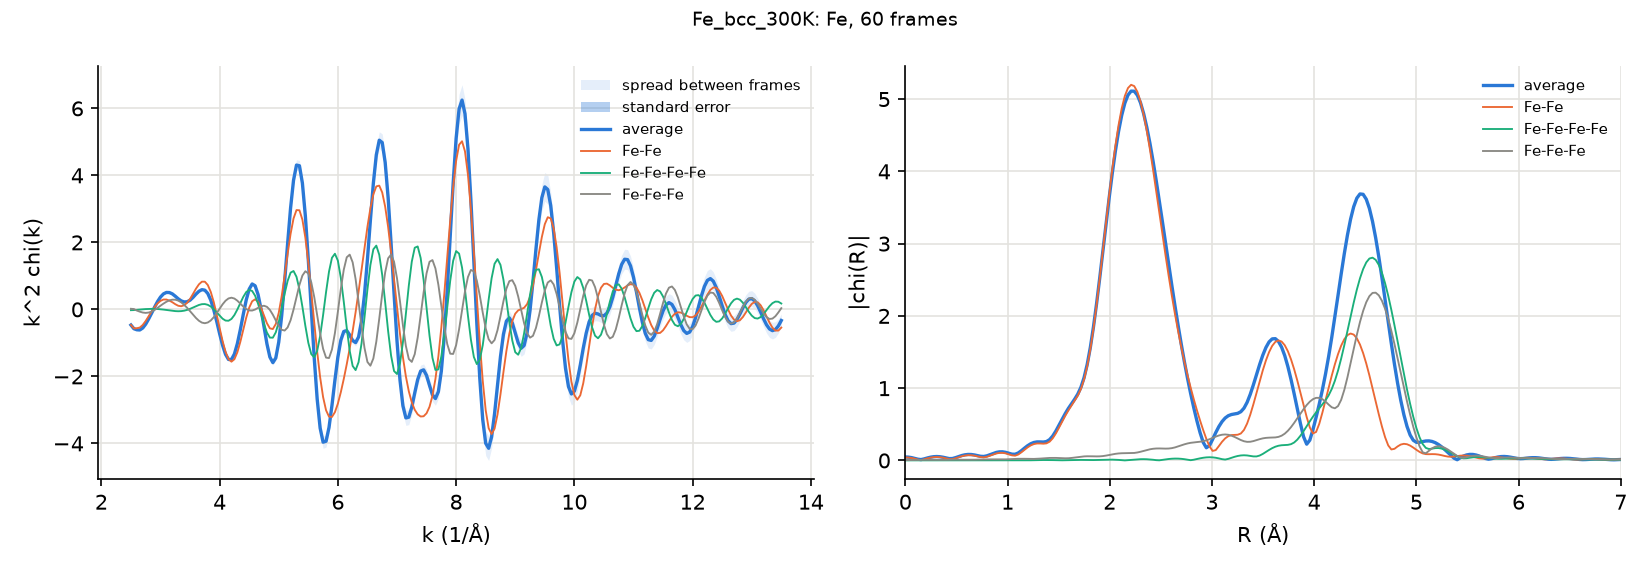

60 frames, 1920 absorbing atoms in all
R-factor between the averages of the first and the second half of the frames: 4.1e-04


In [7]:
import json
from IPython.display import Image, display

OUT = WORK / "mdexafs_out"
display(Image(filename=str(OUT / "average" / f"{ELEMENT}.png"), width=900))
average = json.loads((OUT / "average" / "average.json").read_text())["edges"][ELEMENT]
print(f"{average['n_frames']} frames, {average['absorbers']} absorbing atoms in all")
print(f"R-factor between the averages of the first and the second half of the frames: "
      f"{average['convergence']['split_half_r_factor']:.1e}")

The R-factor between the two halves tells whether enough frames were used: it is the difference between two
independent halves of your data, as a fraction of the signal. If it is not far below the R-factor of the comparison
with the measured spectrum, use more frames or more absorbing atoms per frame.

R-factor: 1.80e-04
S0²: 0.807   interval 0.803 to 0.810   sampling standard error 0.005
ΔE0: 2.08 eV   interval 2.04 to 2.11   sampling standard error 0.02 eV


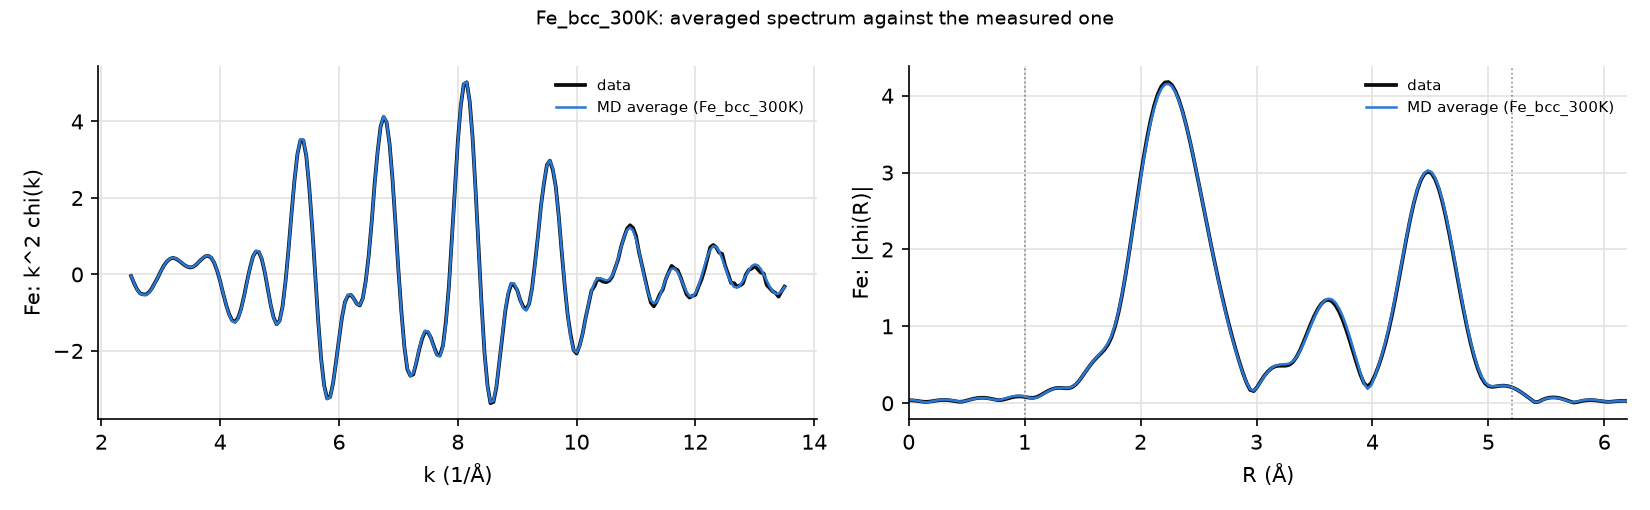

In [8]:
if MEASURED_CHI:
    report = json.loads((OUT / "compare" / "compare.json").read_text())
    shared, spectrum = report["shared"], report["runs"][0]["spectra"][0]
    print(f"R-factor: {spectrum['r_factor']:.2e}")
    print(f"S0²: {shared['s02'][ELEMENT]:.3f}   interval {shared['s02_interval'][ELEMENT][0]:.3f} to "
          f"{shared['s02_interval'][ELEMENT][1]:.3f}   sampling standard error {shared['sampling']['s02_se'][ELEMENT]:.3f}")
    print(f"ΔE0: {shared['de0'][ELEMENT]:.2f} eV   interval {shared['de0_interval'][ELEMENT][0]:.2f} to "
          f"{shared['de0_interval'][ELEMENT][1]:.2f}   sampling standard error {shared['sampling']['de0_se'][ELEMENT]:.2f} eV")
    if shared.get("at_bound"):
        print("ended on a bound, which is not a fit:", shared["at_bound"])
    display(Image(filename=str(OUT / "compare" / "compare.png"), width=900))

S0² and ΔE0 are the only fitted numbers; the structure is that of your trajectory. The interval says how well the
measured spectrum fixes each number with the structure held fixed (90 %); the sampling standard error says how
much it would move with another set of frames ([Comparison](https://github.com/nmarcella/feffGPU/blob/main/docs/md/comparison.md)).

RDF of 60 frames (r_max 6.0 A, bins 0.01 A, device cuda)
  6/60 frames (0.2 s)
  12/60 frames (0.2 s)
  18/60 frames (0.2 s)
  24/60 frames (0.2 s)
  30/60 frames (0.3 s)
  36/60 frames (0.3 s)
  42/60 frames (0.3 s)
  48/60 frames (0.3 s)
  54/60 frames (0.3 s)
  60/60 frames (0.4 s)
RDFs in .../tutorials/my_run/mdexafs_out/rdf


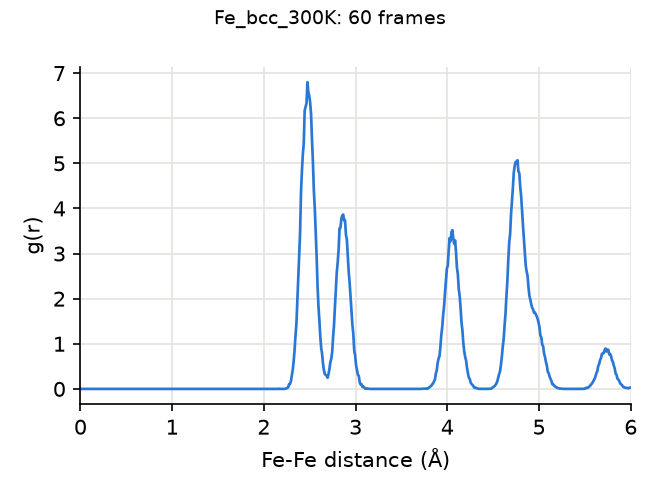

In [9]:
!md-exafs rdf my_run/config.toml
display(Image(filename=str(OUT / "rdf" / "rdf.png"), width=460))

For the numbers of a shell (the number of neighbors, the mean distance, its variance and the third cumulant), add
a `[[rdf.peak]]` block with the two elements and the range of distances to `my_run/config.toml` and run the cell
again ([Analysis of trajectories](https://github.com/nmarcella/feffGPU/blob/main/docs/md/analysis.md)).

## 6. Keep the results

Everything is in `my_run/mdexafs_out`: the averaged spectrum (`average/{element}.chi`), its parts, the comparison,
the radial distributions, and `chi.h5` with the spectrum of every frame ([Outputs](https://github.com/nmarcella/feffGPU/blob/main/docs/md/outputs.md)). The
next cell packs the folder and, on Colab, downloads it.

When you publish results obtained with this package, cite FEFF and the original MD-EXAFS program
([Citing](https://github.com/nmarcella/feffGPU/blob/main/docs/citing.md)).

In [10]:
archive = shutil.make_archive("my_run_results", "zip", WORK)
print("packed:", Path(archive).name)
if IN_COLAB:
    from google.colab import files
    files.download("my_run_results.zip")

packed: my_run_results.zip
